# Lab 6: Geodemographics

## Challenge: Geodemographic Classification
Instructions:

In this challenge, you will replicate the process of creating a geodemographic classification using the k-means clustering algorithm. 

Please select any city in the UK except **London, Liverpool, or Glasgow**. The main goal is to generate a meaningful and informative classification that captures the diversity of areas in your dataset using the census data ( For England, you can try to use the 2021 or 2011 census, and for Scotland, you can use the 2022 or 2011 census data) 

1. Define the main goal for the geodemographic classification (marketing, retail and service planning).  
2. Look for census data from the selected city for which you would like to generate the geodemographic classification.
3. The census data at the Output Area OA level. Select multiple topics of at least four topics (socio-demographics, economics, health, and so on). Describe your topic selection accordingly based on the goal of your geodemographic classification. For example, if your geodemographics are related to marketing, Economic variables might be the appropriate selection. 
4. Identify the variables that will be crucial for effectively segmenting neighbourhoods. Evaluate how this choice may impact the classification results, including **a DEA analysis**.
5. Prepare, adjust or clean the dataset **addressing any missing values or outliers** that could distort the clustering results.
6. Include **standardisation between areas and variables**. Make an appropriate analysis and adjust the variable selection accordingly for any multicollinearity.
7. Utilize the **k-means** clustering algorithm to create a classification based on the selected variables.
8. Define the **optimum number of clusters** (i.e., using the Elblow method). Experiment with different values of k.
9. **Evaluate your cluster groups (e.g., using PCA)** and interpret your cluster centres. Describe your results and repeat the process to adjust the variable selection and cluster groups to provide more meaningful results for your geodemographic goal. Interpret the characteristics of each cluster. **What demographic patterns or similarities are prevalent within each group?**
10. **Map the final cluster groups**
11. Finish the analysis by **naming the final clusters and plotting a final map that includes the census values and the provided names**.
12. Finally, acknowledge the subjective nature of classification and make analytical decisions to produce an optimum classification for your specific purpose. Reflect on the challenges and insights gained during the classification process. Ensure you document your analytical decisions and the rationale behind any important decision. Once your geodemographics are constructed, **describe the potential use cases for the geodemographic classification you have built** based on your initial goal.

### Step 1: Classification goal and research question
For this challenge I have chosen Bristol (because i am familiar with the location already) to analyse how neighbourhoods can be grouped according to their demographic, socioeconomic, health and housing characteristics - the aim is to identify areas with similar characteristics instead of just grouping them based on their geographical location.
Then i have decided to focus on community service planning because understanding differences in neighbourhood populations could be helpful for informing decisions about the types of services and infrastructure needed across a city e.g. areas with higher older populations could have different potential service requirements in comparison to areas with more younger residents or households with different housing situationsResearch Question

Hence my proposed research question/topic is:
How can Bristol's 2021 Census Output Areas be classified into distinct geodemographic neighbourhood types using demographic, economic, health and housing characteristics -and how could these classifications inform local community service planning?
Workflow thought proccess for answering this research question:
Plan to use the 2021 Census data at Output Area (OA) level (will allow the classification to reflect differences between smaller areas rather than larger wards/districts). Then using the methods from Lab 6, I will select variables from several census topics which are relevant to the classification goal- then I will look at their distributions, and check for missing values and any potential outliers, and then explore any potential correlations before standardising the selected variables. Next i will use k-means clustering (as per lab 6) to group the Output Areas with similar characteristics, and also experiemnt with different numbers of clusters using the elbow method (aslo as per lab 6). The groups will then be analysed using PCA as per requested and their cluster centres to assess how meaningful + distinct they are. Then finally, I will name the resulting neighbourhood types based on their characteristics and then map their distribution across Bristol, before then considering their potential applications and limitations for community service planning in hopes of answering the research question fully.

### Step 2:Selecting the study area and obtaining census data
I decided to use Open Data Bristol and find the Bristol City Council administrative area rather than focusing on a smaller selection of neighbourhoods, so that the classification could investigate differences across the city. Then I am using data from the 2021 Census for England and Wales (by the Office for National Statistics (ONS)) and available and downloaded through Nomis.
Following the method introduced in Lab 6 Part 2 I will use Output Areas (OAs) as the geographical units for the classification - since these are relatively small census areas, allowing more detailed differences to be identified than if I used larger wards or districts which was the plan. Then I downloaded the 2021 Bristol Output Area boundaries from Bristol City Council's Open Data portal, and the census tables were obtained from the official Nomis Census 2021 bulk downloads. I plan to use the OA codes to connect the census information to the correct geographical boundaries.

#### Data Sources

- **Bristol City Council:** [Output Areas 2021 (Precise)](https://opendata.bristol.gov.uk/maps/3f84a7889cf949fdb1f9083800b9251f) — geographical boundaries.
- **ONS / Nomis:** [Census 2021 bulk downloads](https://www.nomisweb.co.uk/census/2021/bulk) — census population and household data.

The classification will use 2021 census data throughout -so the variables and geographical boundaries refer to the same census perio

In [46]:
#setting up for the rest of the code:
# importing the libraries used in the Lab 6 geodemographic classification examples - (following the imports demonstrated in Lab 6, cells 7 and 42)

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

In [47]:
#next we need to be loading the Bristol 2021 Output Area boundaries using GeoPandas
# I need the boundaries to identify which areas are in Bristol and to map the final classification
# (has been adapted from Lab 6, cell 42, which loads the Glasgow OA shapefile) - I changed the file path and variable names for the Bristol GeoJSON


shp_path = "data/Output_areas_2021_(Precise).geojson"
bristol_oa = gpd.read_file(shp_path)

print("Number of Bristol Output Areas:", len(bristol_oa))
print("CRS:", bristol_oa.crs)
print("Columns:", bristol_oa.columns.tolist())

bristol_oa.head()


Number of Bristol Output Areas: 1405
CRS: EPSG:4326
Columns: ['OBJECTID', 'OA21CD', 'WardCD', 'Wardname', 'ShapeSTArea', 'ShapeSTLength', 'geometry']


,OBJECTID,OA21CD,WardCD,Wardname,ShapeSTArea,ShapeSTLength,geometry
0,1,E00073143,E05010885,Ashley,21727.75,732.76,"POLYGON ((-2.57215 51.46904, -2.57239 51.46911..."
1,2,E00073145,E05010885,Ashley,18632.56,895.28,"POLYGON ((-2.58394 51.46394, -2.58394 51.46388..."
2,3,E00073147,E05010885,Ashley,62079.29,1555.29,"POLYGON ((-2.57928 51.46324, -2.57908 51.46340..."
3,4,E00073148,E05010885,Ashley,22655.62,761.24,"POLYGON ((-2.58730 51.46363, -2.58727 51.46355..."
4,5,E00073150,E05010885,Ashley,51099.33,1558.82,"POLYGON ((-2.57724 51.46633, -2.57727 51.46632..."


### Step 3:Chosing the census topics
Following Lab 6 Part 2, I decided to use four different Census 2021 topics to represent different characteristics of Bristol's neighbourhoods.
Since my aim is to investigate neighbourhood differences relevant to community service planning, I decided to choose the following four topics which i thought would work well together and would give some good results given the content of the research question:

| Census topic | Dataset | Reason for selection |
|---|---|---|
| *Age* | TS007A | To look at the differences between younger and older populations as they may have different potential service requirements |
| *Economic activity* | TS066 | To consider differences in employment circumstances across neighbourhoods. |
| *General health* | TS037 | To look at the variation in reported health as it could be relevant to understanding the different community needs |
| *Housing tenure* | TS054 | To find the areas with different housing characteristics-  especially private and social renting |

So, i have chosen these 4 datasets because they represent different aspects of neighbourhood characteristics and are relevant to my original classification goal - I will later decide which individual variables to keep to use and assess before applying the clustering methods later in the code.

In [49]:
# loading the 2021 Census age data at Output Area level - this contains the different age categories which I can use to compare the age characteristics of Bristol's neighbourhoods
# Following the CSV loading method from Lab 6, cells 40-42, and using .isin() from Lab 5 to keep only the Bristol OAs

age = pd.read_csv("data/census2021-ts007a-oa.csv", low_memory=False)

# Keeping only the OAs which match the Bristol boundary dataset
age = age[age["geography code"].isin(bristol_oa["OA21CD"])].copy()

print("Bristol age records:", len(age))
print("Columns:", age.columns.tolist())

age.head()

Bristol age records: 1405
Columns: ['date', 'geography', 'geography code', 'Age: Total', 'Age: Aged 4 years and under', 'Age: Aged 5 to 9 years', 'Age: Aged 10 to 14 years', 'Age: Aged 15 to 19 years', 'Age: Aged 20 to 24 years', 'Age: Aged 25 to 29 years', 'Age: Aged 30 to 34 years', 'Age: Aged 35 to 39 years', 'Age: Aged 40 to 44 years', 'Age: Aged 45 to 49 years', 'Age: Aged 50 to 54 years', 'Age: Aged 55 to 59 years', 'Age: Aged 60 to 64 years', 'Age: Aged 65 to 69 years', 'Age: Aged 70 to 74 years', 'Age: Aged 75 to 79 years', 'Age: Aged 80 to 84 years', 'Age: Aged 85 years and over']


,date,geography,geography code,Age: Total,Age: Aged 4 years and under,Age: Aged 5 to 9 years,Age: Aged 10 to 14 years,Age: Aged 15 to 19 years,Age: Aged 20 to 24 years,Age: Aged 25 to 29 years,...,Age: Aged 40 to 44 years,Age: Aged 45 to 49 years,Age: Aged 50 to 54 years,Age: Aged 55 to 59 years,Age: Aged 60 to 64 years,Age: Aged 65 to 69 years,Age: Aged 70 to 74 years,Age: Aged 75 to 79 years,Age: Aged 80 to 84 years,Age: Aged 85 years and over
68976,2021,E00073143,E00073143,359,17,10,15,15,32,54,...,30,20,16,14,14,13,8,8,1,1
68977,2021,E00073145,E00073145,420,20,24,24,30,56,79,...,22,23,23,17,8,2,7,4,2,1
68978,2021,E00073147,E00073147,538,33,30,48,43,43,65,...,35,32,22,26,20,12,7,6,11,4
68979,2021,E00073148,E00073148,296,7,9,7,16,46,73,...,10,16,17,10,9,4,1,2,0,1
68980,2021,E00073150,E00073150,462,16,21,12,30,52,76,...,38,24,24,32,21,10,4,4,6,3


In [50]:
#next I am doing the same and loading the economic activity dataset for Bristol- which will allow me to investigate differences in employment circumstances across the OAs
# Using pd.read_csv() from Lab 6, cells 40-42, and the same .isin() filtering method from Lab 5

economic = pd.read_csv("data/census2021-ts066-oa.csv", low_memory=False)

# Filtering the national census data to the Bristol study area
economic = economic[economic["geography code"].isin(bristol_oa["OA21CD"])].copy()

print("Bristol economic activity records:", len(economic))
print("Columns:", economic.columns.tolist())

economic.head()


Bristol economic activity records: 1405
Columns: ['date', 'geography', 'geography code', 'Economic activity status: Total: All usual residents aged 16 years and over', 'Economic activity status: Economically active (excluding full-time students)', 'Economic activity status: Economically active (excluding full-time students):In employment', 'Economic activity status: Economically active (excluding full-time students):In employment:Employee', 'Economic activity status: Economically active (excluding full-time students): In employment: Employee: Part-time', 'Economic activity status: Economically active (excluding full-time students): In employment: Employee: Full-time', 'Economic activity status: Economically active (excluding full-time students):In employment:Self-employed with employees', 'Economic activity status: Economically active (excluding full-time students): In employment: Self-employed with employees: Part-time', 'Economic activity status: Economically active (excluding full-t

,date,geography,geography code,Economic activity status: Total: All usual residents aged 16 years and over,Economic activity status: Economically active (excluding full-time students),Economic activity status: Economically active (excluding full-time students):In employment,Economic activity status: Economically active (excluding full-time students):In employment:Employee,Economic activity status: Economically active (excluding full-time students): In employment: Employee: Part-time,Economic activity status: Economically active (excluding full-time students): In employment: Employee: Full-time,Economic activity status: Economically active (excluding full-time students):In employment:Self-employed with employees,...,Economic activity status: Economically active and a full-time student:In employment:Self-employed without employees,Economic activity status: Economically active and a full-time student: In employment: Self-employed without employees: Part-time,Economic activity status: Economically active and a full-time student: In employment: Self-employed without employees: Full-time,Economic activity status: Economically active and a full-time student: Unemployed,Economic activity status: Economically inactive,Economic activity status: Economically inactive: Retired,Economic activity status: Economically inactive: Student,Economic activity status: Economically inactive: Looking after home or family,Economic activity status: Economically inactive: Long-term sick or disabled,Economic activity status: Economically inactive: Other
68976,2021,E00073143,E00073143,317,242,228,182,45,137,7,...,1,1,0,1,72,25,26,7,6,8
68977,2021,E00073145,E00073145,343,210,193,162,38,124,2,...,0,0,0,7,116,15,51,21,14,15
68978,2021,E00073147,E00073147,414,259,243,196,56,140,3,...,1,1,0,5,136,33,27,40,16,20
68979,2021,E00073148,E00073148,268,189,180,158,32,126,1,...,0,0,0,5,64,8,24,4,15,13
68980,2021,E00073150,E00073150,407,292,277,233,54,179,3,...,1,1,0,2,103,22,26,20,19,16


In [51]:
#next up is loading the general health data from the 2021 Census- I chose this topic because differences in reported health may be relevant to potential community service needs
# Following the CSV loading from Lab 6, cells 40-42, and .isin() filtering as used in Lab 5

health = pd.read_csv("data/census2021-ts037-oa.csv", low_memory=False)

# Keeping the Bristol Output Areas
health = health[health["geography code"].isin(bristol_oa["OA21CD"])].copy()

print("Bristol health records:", len(health))
print("Columns:", health.columns.tolist())

health.head()


Bristol health records: 1405
Columns: ['date', 'geography', 'geography code', 'General health: Total: All usual residents', 'General health: Very good health', 'General health: Good health', 'General health: Fair health', 'General health: Bad health', 'General health: Very bad health']


,date,geography,geography code,General health: Total: All usual residents,General health: Very good health,General health: Good health,General health: Fair health,General health: Bad health,General health: Very bad health
68976,2021,E00073143,E00073143,361,180,143,27,9,2
68977,2021,E00073145,E00073145,415,215,137,48,12,3
68978,2021,E00073147,E00073147,537,275,182,53,20,7
68979,2021,E00073148,E00073148,292,150,92,39,7,4
68980,2021,E00073150,E00073150,461,202,174,65,14,6


In [52]:
#then lastly I am loading the housing tenure dataset - aims to help distinguish neighbourhoods with different household characteristics such as private and social renting
# Following Lab 6, cells 40-42, and using the .isin() filtering method from Lab 5

housing = pd.read_csv("data/census2021-ts054-oa.csv", low_memory=False)

# Selecting the census records which belong to Bristol
housing = housing[housing["geography code"].isin(bristol_oa["OA21CD"])].copy()

print("Bristol housing records:", len(housing))
print("Columns:", housing.columns.tolist())

housing.head()


Bristol housing records: 1405
Columns: ['date', 'geography', 'geography code', 'Tenure of household: Total: All households', 'Tenure of household: Owned', 'Tenure of household: Owned: Owns outright', 'Tenure of household: Owned: Owns with a mortgage or loan', 'Tenure of household: Shared ownership', 'Tenure of household: Shared ownership: Shared ownership', 'Tenure of household: Social rented', 'Tenure of household: Social rented: Rents from council or Local Authority', 'Tenure of household: Social rented: Other social rented', 'Tenure of household: Private rented', 'Tenure of household: Private rented: Private landlord or letting agency', 'Tenure of household: Private rented: Other private rented', 'Tenure of household: Lives rent free']


,date,geography,geography code,Tenure of household: Total: All households,Tenure of household: Owned,Tenure of household: Owned: Owns outright,Tenure of household: Owned: Owns with a mortgage or loan,Tenure of household: Shared ownership,Tenure of household: Shared ownership: Shared ownership,Tenure of household: Social rented,Tenure of household: Social rented: Rents from council or Local Authority,Tenure of household: Social rented: Other social rented,Tenure of household: Private rented,Tenure of household: Private rented: Private landlord or letting agency,Tenure of household: Private rented: Other private rented,Tenure of household: Lives rent free
68976,2021,E00073143,E00073143,148,91,41,50,5,5,10,4,6,42,34,8,0
68977,2021,E00073145,E00073145,158,23,11,12,0,0,69,27,42,65,61,4,1
68978,2021,E00073147,E00073147,171,86,41,45,0,0,40,10,30,45,40,5,0
68979,2021,E00073148,E00073148,142,23,11,12,1,1,38,9,29,80,77,3,0
68980,2021,E00073150,E00073150,191,89,39,50,1,1,51,24,27,49,45,4,1


### Step 4:Selecting and evaluating the variables

Now that I have chosen my 4 census topics, I now need to select the individual variables which will be useful for distinguishing different types of neighbourhoods in Bristol.
And so for the following, i am using the variable selection and descriptive analysis methods in Lab 6 Part 2 as a guide and I decided to start with six variables which I thought would represent different population and housing characteristics relevant to community service planning.

| Census topic | Selected variable | Reason |
|---|---|---|
| Age | % aged 20–24 | To help find the areas with higher proportions of younger adults |
| Age | % aged 65+ | To help find areas with larger older populations |
| Economic activity | % of residents aged 16+ who are unemployed | To help represnt the differences in economic activity |
| General health | % reporting bad or very bad health | To help analyse differences in reported health characteristics |
| Housing tenure | % of households privately renting | To help fins areas with higher private-renting proportions |
| Housing tenure | % of households socially renting | To help find a different type of housing-tenure characteristic |

I have chosen to use percentages rather than the original census counts (following the explanation in Lab 6) because the Output Areas contained different numbers of residents and households - so by doing this, it should make the characteristics a bit more comparable between areas. Some of the selected variables require several census categories to be combined e.g.  the population aged 65 and over and the two unemployment categories - so i wwill also make sure that each % is calculated using the correct population or household total. Then after creating the 6 indicators, I will then  analyse their descriptive statistics and distributions to assess whether they have any  meaningful variation and if any unusual values need further investigation before clustering.

In [53]:
#First I am selecting the age and economic activity columns that I want to use for the classification - I need to keep the total population columns as well, as these will be used to calculate the percentages later
# Following the variable selection/subsetting approach in Lab 6, cells 56-57 and 63, but using my Bristol census columns

age_cols = [
    "geography code",
    "Age: Total",
    "Age: Aged 20 to 24 years",
    "Age: Aged 65 to 69 years",
    "Age: Aged 70 to 74 years",
    "Age: Aged 75 to 79 years",
    "Age: Aged 80 to 84 years",
    "Age: Aged 85 years and over"
]

economic_cols = [
    "geography code",
    "Economic activity status: Total: All usual residents aged 16 years and over",
    "Economic activity status: Economically active (excluding full-time students): Unemployed",
    "Economic activity status: Economically active and a full-time student: Unemployed"
]

# here i am creating smaller datasets with just these selected columns
# I am keeping both unemployed categories so that unemployed full-time students are not missed out
age_selected = age[age_cols].copy()
economic_selected = economic[economic_cols].copy()

print("Age dataset:", age_selected.shape)
print("Economic activity dataset:", economic_selected.shape)

age_selected.head()

Age dataset: (1405, 8)
Economic activity dataset: (1405, 4)


,geography code,Age: Total,Age: Aged 20 to 24 years,Age: Aged 65 to 69 years,Age: Aged 70 to 74 years,Age: Aged 75 to 79 years,Age: Aged 80 to 84 years,Age: Aged 85 years and over
68976,E00073143,359,32,13,8,8,1,1
68977,E00073145,420,56,2,7,4,2,1
68978,E00073147,538,43,12,7,6,11,4
68979,E00073148,296,46,4,1,2,0,1
68980,E00073150,462,52,10,4,4,6,3


In [54]:
#next up, I am doing the same for the general health and housing tenure datasets
# For health I want to combine bad and very bad health, and for housing I want to compare private and social renting- I am also keeping their corresponding totals so I can calculate the correct percentages
# Following the same variable subsetting approach from Lab 6, cells 56-57 and 63

health_cols = [
    "geography code",
    "General health: Total: All usual residents",
    "General health: Bad health",
    "General health: Very bad health"
]

housing_cols = [
    "geography code",
    "Tenure of household: Total: All households",
    "Tenure of household: Private rented",
    "Tenure of household: Social rented"
]

health_selected = health[health_cols].copy()
housing_selected = housing[housing_cols].copy()

print("Health dataset:", health_selected.shape)
print("Housing dataset:", housing_selected.shape)

health_selected.head()

Health dataset: (1405, 4)
Housing dataset: (1405, 4)


,geography code,General health: Total: All usual residents,General health: Bad health,General health: Very bad health
68976,E00073143,361,9,2
68977,E00073145,415,12,3
68978,E00073147,537,20,7
68979,E00073148,292,7,4
68980,E00073150,461,14,6


In [55]:
# Now I need to combine my four selected census datasets with the Bristol Output Area boundaries -i am using the OA codes to join them so that the census values are matched to the correct geographical areas
# Following the GeoDataFrame merge method from Lab 6, cell 42, but repeating it for my four census tables- I am using left joins to keep the Bristol boundaries and then checking if any census values are missing

# Starting with the age dataset:
merged_data = bristol_oa.merge(
    age_selected, left_on="OA21CD", right_on="geography code", how="left"
).drop(columns="geography code")

# Adding the economic activity dataset:
merged_data = merged_data.merge(
    economic_selected, left_on="OA21CD", right_on="geography code", how="left"
).drop(columns="geography code")

# Adding the general health dataset:
merged_data = merged_data.merge(
    health_selected, left_on="OA21CD", right_on="geography code", how="left"
).drop(columns="geography code")

# Finally adding the housing tenure dataset:
merged_data = merged_data.merge(
    housing_selected, left_on="OA21CD", right_on="geography code", how="left"
).drop(columns="geography code")

# Checking that all 1405 Bristol OAs have been kept and that the joins worked
print("Merged dataset shape:", merged_data.shape)
print("Unique Output Areas:", merged_data["OA21CD"].nunique())
print("Missing values:", merged_data.isna().sum().sum())

merged_data.head()

Merged dataset shape: (1405, 23)
Unique Output Areas: 1405
Missing values: 0


,OBJECTID,OA21CD,WardCD,Wardname,ShapeSTArea,ShapeSTLength,geometry,Age: Total,Age: Aged 20 to 24 years,Age: Aged 65 to 69 years,...,Age: Aged 85 years and over,Economic activity status: Total: All usual residents aged 16 years and over,Economic activity status: Economically active (excluding full-time students): Unemployed,Economic activity status: Economically active and a full-time student: Unemployed,General health: Total: All usual residents,General health: Bad health,General health: Very bad health,Tenure of household: Total: All households,Tenure of household: Private rented,Tenure of household: Social rented
0,1,E00073143,E05010885,Ashley,21727.75,732.76,"POLYGON ((-2.57215 51.46904, -2.57239 51.46911...",359,32,13,...,1,317,14,1,361,9,2,148,42,10
1,2,E00073145,E05010885,Ashley,18632.56,895.28,"POLYGON ((-2.58394 51.46394, -2.58394 51.46388...",420,56,2,...,1,343,17,7,415,12,3,158,65,69
2,3,E00073147,E05010885,Ashley,62079.29,1555.29,"POLYGON ((-2.57928 51.46324, -2.57908 51.46340...",538,43,12,...,4,414,16,5,537,20,7,171,45,40
3,4,E00073148,E05010885,Ashley,22655.62,761.24,"POLYGON ((-2.58730 51.46363, -2.58727 51.46355...",296,46,4,...,1,268,9,5,292,7,4,142,80,38
4,5,E00073150,E05010885,Ashley,51099.33,1558.82,"POLYGON ((-2.57724 51.46633, -2.57727 51.46632...",462,52,10,...,3,407,15,2,461,14,6,191,49,51


In [56]:
#since some of the variables I have chosen are made up of several census categories I need to first add these together 
# This will give me the total population aged 65+, total unemployed residents and those reporting bad or very bad health -this prepares the values for the percentage calculations demonstrated in Lab 6, cell 57
# (The additions below are adapted to the categories available in the Bristol 2021 census data)

# first combining the five age categories to get the total number of residents aged 65+:
merged_data["Age_65plus"] = (
    merged_data["Age: Aged 65 to 69 years"]
    + merged_data["Age: Aged 70 to 74 years"]
    + merged_data["Age: Aged 75 to 79 years"]
    + merged_data["Age: Aged 80 to 84 years"]
    + merged_data["Age: Aged 85 years and over"]
)

# then adding the two unemployed categories together, including unemployed full-time students:
merged_data["Unemployed_total"] = (
    merged_data["Economic activity status: Economically active (excluding full-time students): Unemployed"]
    + merged_data["Economic activity status: Economically active and a full-time student: Unemployed"]
)

# then combining bad and very bad general health into one category:
merged_data["Poor_health_total"] = (
    merged_data["General health: Bad health"]
    + merged_data["General health: Very bad health"]
)

# Checking the new combined values before using them to calculate percentages
merged_data[
    ["OA21CD", "Age_65plus", "Unemployed_total", "Poor_health_total"]
].head()

,OA21CD,Age_65plus,Unemployed_total,Poor_health_total
0,E00073143,31,15,11
1,E00073145,16,24,15
2,E00073147,40,21,27
3,E00073148,8,14,11
4,E00073150,27,17,20


In [57]:
# now I am converting the six selected census variables into percentages - and this is important because the OAs have different population and household totals, so using raw counts would not be as comparable
# I am using the calculate_percentages() function directly from Lab 6, cell 57 and I have only changed the total_cols and value_cols lists to match the variables in my Bristol datasets

# using the percentage calculation function from Lab 6, cell 57:
def calculate_percentages(dataframe, total_columns, value_columns):

    result_df = pd.DataFrame()

    for total_col, value_col in zip(total_columns, value_columns):
        percentage_col_name = f"{value_col}_percentage"

        if total_col not in dataframe.columns:
            raise ValueError(f"Total column '{total_col}' not found in the DataFrame.")

        # Converting the census values to numeric, as some census data may contain missing or non-numeric entries
        dataframe[value_col] = pd.to_numeric(dataframe[value_col], errors='coerce')
        dataframe[total_col] = pd.to_numeric(dataframe[total_col], errors='coerce')

        result_df[percentage_col_name] = (dataframe[value_col] / dataframe[total_col]) * 100

    return result_df

#then choosing the correct census total for each of my six variables next:
# age and health use population totals, unemployment uses residents aged 16+, and renting uses households so:
total_cols = [
    "Age: Total",
    "Age: Total",
    "Economic activity status: Total: All usual residents aged 16 years and over",
    "General health: Total: All usual residents",
    "Tenure of household: Total: All households",
    "Tenure of household: Total: All households"
]

# these are the counts I want to convert into percentages using the totals above:
value_cols = [
    "Age: Aged 20 to 24 years",
    "Age_65plus",
    "Unemployed_total",
    "Poor_health_total",
    "Tenure of household: Private rented",
    "Tenure of household: Social rented"
]

result_dataframe = calculate_percentages(merged_data, total_cols, value_cols)

print("Percentage dataset shape:", result_dataframe.shape)

result_dataframe.head().round(2)

Percentage dataset shape: (1405, 6)


,Age: Aged 20 to 24 years_percentage,Age_65plus_percentage,Unemployed_total_percentage,Poor_health_total_percentage,Tenure of household: Private rented_percentage,Tenure of household: Social rented_percentage
0,8.91,8.64,4.73,3.05,28.38,6.76
1,13.33,3.81,7.00,3.61,41.14,43.67
2,7.99,7.43,5.07,5.03,26.32,23.39
3,15.54,2.70,5.22,3.77,56.34,26.76
4,11.26,5.84,4.18,4.34,25.65,26.70


##### Descriptive exploratory analysis
Now that I have calculated the six percentage variables, I want to look at their distributions and descriptive statistics before using them for clustering. So, following the DEA examples in Lab 6 Part 2, I will first combine the calculated %s with the Bristol census data and then select the variables needed for the classification. So that i can then use summary statistics and violin plots to see how much the variables differ between the Output Areas and whether there are any particularly high or low values. The aim is that this will help me understand the characteristics of the data and whether or not any of the variables might need further investigation before running k-means.

In [58]:
#now that I have calculated the percentages, I am adding these back onto my merged Bristol census dataset-I am using pd.concat() from Lab 6, cell 60 to combine the two DataFrames
# Since the percentages were calculated directly from merged_data, the rows/indexes should still match the same OAs

concatenated_df = pd.concat([merged_data, result_dataframe], axis=1, ignore_index=False)

print("Combined dataset shape:", concatenated_df.shape)

concatenated_df.head()

Combined dataset shape: (1405, 32)


,OBJECTID,OA21CD,WardCD,Wardname,ShapeSTArea,ShapeSTLength,geometry,Age: Total,Age: Aged 20 to 24 years,Age: Aged 65 to 69 years,...,Tenure of household: Social rented,Age_65plus,Unemployed_total,Poor_health_total,Age: Aged 20 to 24 years_percentage,Age_65plus_percentage,Unemployed_total_percentage,Poor_health_total_percentage,Tenure of household: Private rented_percentage,Tenure of household: Social rented_percentage
0,1,E00073143,E05010885,Ashley,21727.75,732.76,"POLYGON ((-2.57215 51.46904, -2.57239 51.46911...",359,32,13,...,10,31,15,11,8.91,8.64,4.73,3.05,28.38,6.76
1,2,E00073145,E05010885,Ashley,18632.56,895.28,"POLYGON ((-2.58394 51.46394, -2.58394 51.46388...",420,56,2,...,69,16,24,15,13.33,3.81,7.00,3.61,41.14,43.67
2,3,E00073147,E05010885,Ashley,62079.29,1555.29,"POLYGON ((-2.57928 51.46324, -2.57908 51.46340...",538,43,12,...,40,40,21,27,7.99,7.43,5.07,5.03,26.32,23.39
3,4,E00073148,E05010885,Ashley,22655.62,761.24,"POLYGON ((-2.58730 51.46363, -2.58727 51.46355...",296,46,4,...,38,8,14,11,15.54,2.70,5.22,3.77,56.34,26.76
4,5,E00073150,E05010885,Ashley,51099.33,1558.82,"POLYGON ((-2.57724 51.46633, -2.57727 51.46632...",462,52,10,...,51,27,17,20,11.26,5.84,4.18,4.34,25.65,26.70


In [59]:
#next up I am selecting just the six percentage variables that I want to use for the classification andI am also keeping the OA codes, ward names and geometry as these will be useful for mapping the results later
# Following the keep_cols example from Lab 6, cell 63, but using my Bristol census variables, then the geographical columns are being kept for my ownreference and will not be included as inputs for k-means

keep_cols = [
    "OA21CD",
    "Wardname",
    "geometry",
    "Age: Aged 20 to 24 years_percentage",
    "Age_65plus_percentage",
    "Unemployed_total_percentage",
    "Poor_health_total_percentage",
    "Tenure of household: Private rented_percentage",
    "Tenure of household: Social rented_percentage"
]

bristol_census_data = concatenated_df[keep_cols].copy()

print("Selected dataset shape:", bristol_census_data.shape)

bristol_census_data.head()


Selected dataset shape: (1405, 9)


,OA21CD,Wardname,geometry,Age: Aged 20 to 24 years_percentage,Age_65plus_percentage,Unemployed_total_percentage,Poor_health_total_percentage,Tenure of household: Private rented_percentage,Tenure of household: Social rented_percentage
0,E00073143,Ashley,"POLYGON ((-2.57215 51.46904, -2.57239 51.46911...",8.91,8.64,4.73,3.05,28.38,6.76
1,E00073145,Ashley,"POLYGON ((-2.58394 51.46394, -2.58394 51.46388...",13.33,3.81,7.00,3.61,41.14,43.67
2,E00073147,Ashley,"POLYGON ((-2.57928 51.46324, -2.57908 51.46340...",7.99,7.43,5.07,5.03,26.32,23.39
3,E00073148,Ashley,"POLYGON ((-2.58730 51.46363, -2.58727 51.46355...",15.54,2.70,5.22,3.77,56.34,26.76
4,E00073150,Ashley,"POLYGON ((-2.57724 51.46633, -2.57727 51.46632...",11.26,5.84,4.18,4.34,25.65,26.70


In [60]:
#then I am now giving the six % variables shorter names because the others were way too long and so this is to make them easier to use in the rest of the analysis
# Following the short_column_names and rename method demonstrated in Lab 6, cell 65

short_column_names = {
    "Age: Aged 20 to 24 years_percentage": "Age_20to24",
    "Age_65plus_percentage": "Age_65plus",
    "Unemployed_total_percentage": "Unemployed",
    "Poor_health_total_percentage": "Poor_Health",
    "Tenure of household: Private rented_percentage": "Private_Rent",
    "Tenure of household: Social rented_percentage": "Social_Rent"
}

bristol_census_data = bristol_census_data.rename(columns=short_column_names)

print("Columns in the selected dataset:")
print(bristol_census_data.columns.tolist())

bristol_census_data.head().round(2)


Columns in the selected dataset:
['OA21CD', 'Wardname', 'geometry', 'Age_20to24', 'Age_65plus', 'Unemployed', 'Poor_Health', 'Private_Rent', 'Social_Rent']


,OA21CD,Wardname,geometry,Age_20to24,Age_65plus,Unemployed,Poor_Health,Private_Rent,Social_Rent
0,E00073143,Ashley,"POLYGON ((-2.57215 51.46904, -2.57239 51.46911...",8.91,8.64,4.73,3.05,28.38,6.76
1,E00073145,Ashley,"POLYGON ((-2.58394 51.46394, -2.58394 51.46388...",13.33,3.81,7.00,3.61,41.14,43.67
2,E00073147,Ashley,"POLYGON ((-2.57928 51.46324, -2.57908 51.46340...",7.99,7.43,5.07,5.03,26.32,23.39
3,E00073148,Ashley,"POLYGON ((-2.58730 51.46363, -2.58727 51.46355...",15.54,2.70,5.22,3.77,56.34,26.76
4,E00073150,Ashley,"POLYGON ((-2.57724 51.46633, -2.57727 51.46632...",11.26,5.84,4.18,4.34,25.65,26.70


In [61]:
#next i am now using descriptive statistics to see how the six & variables differ across Bristol's OAs
# Following the .describe() method from Lab 6, cell 51
# I want to look at the mean, standard deviation, quartiles and max/min values beacuse this should help me identify which variables have a large spread and which might contain unusual values

variables = [
    "Age_20to24",
    "Age_65plus",
    "Unemployed",
    "Poor_Health",
    "Private_Rent",
    "Social_Rent"
]

bristol_census_data[variables].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Age_20to24,1405.0,9.65,9.16,0.00,4.65,6.49,10.31,65.44
Age_65plus,1405.0,13.51,8.66,0.00,7.34,12.03,17.36,84.36
Unemployed,1405.0,3.47,2.06,0.00,2.11,3.11,4.49,13.48
Poor_Health,1405.0,5.12,3.53,0.00,2.63,4.32,6.79,28.57
Private_Rent,1405.0,25.61,18.41,1.18,11.41,19.66,36.08,92.36
Social_Rent,1405.0,18.97,21.74,0.00,2.50,9.02,30.17,97.41


C:\Users\elisa\miniforge3\envs\ua\lib\site-packages\seaborn\_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
C:\Users\elisa\miniforge3\envs\ua\lib\site-packages\seaborn\_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
C:\Users\elisa\miniforge3\envs\ua\lib\site-packages\seaborn\_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
C:\Users\elisa\miniforge3\envs\ua\lib\site-pac

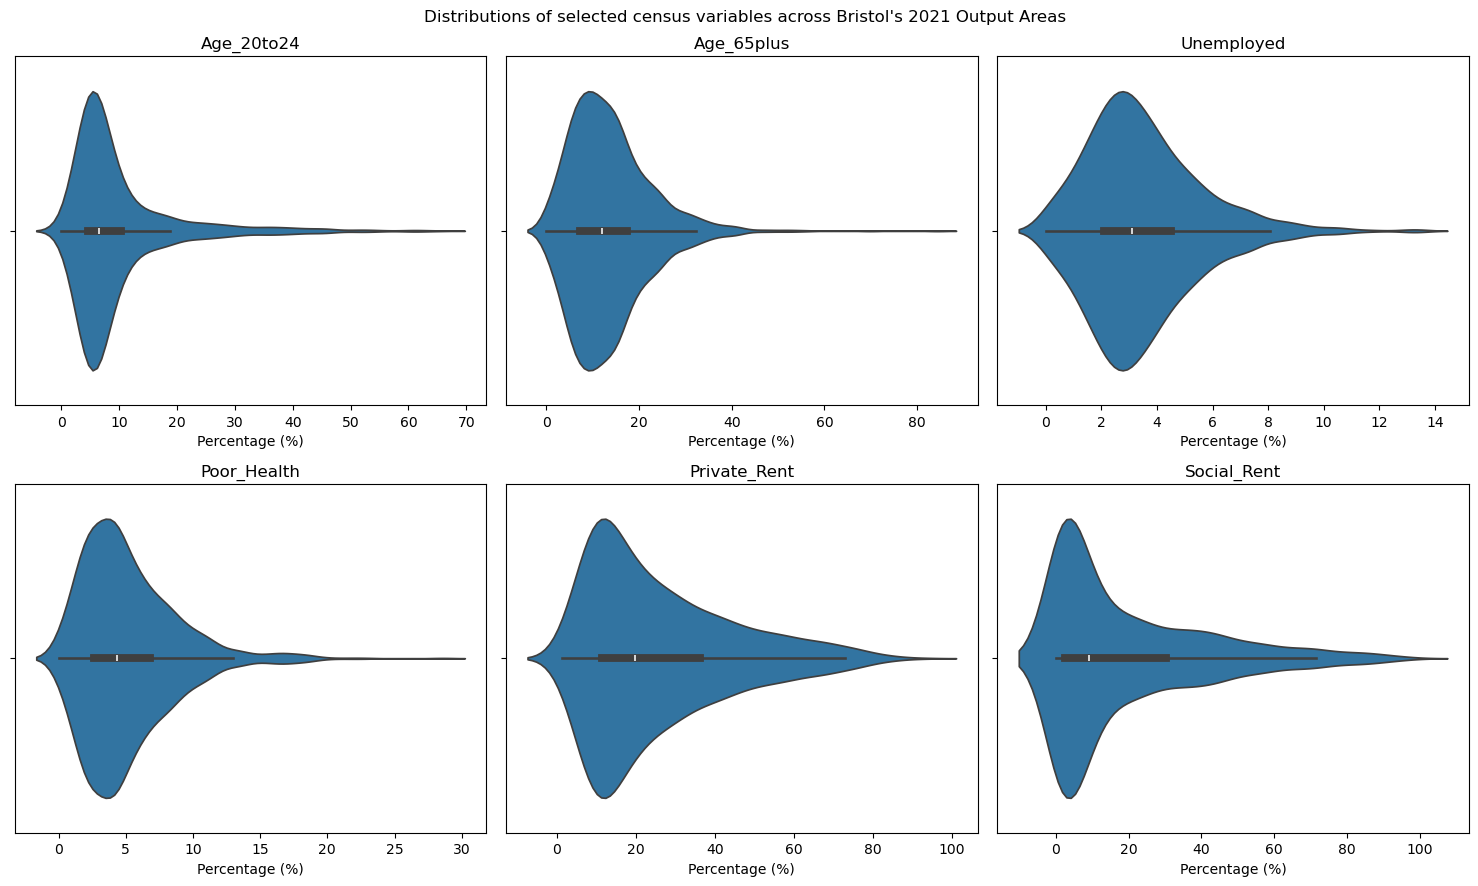

In [62]:
# next is plotting the distribution of each of my 6 census variables using the violin plots demonstrated in Lab 6, cell 53
# I have adapted the lab 6 2x2 subplot layout to 2x3 because I am using 6 variables - and this should hipefully help show whether the percentages are spread evenly or if some have long tails/particularly extreme values
# I plannign to use these plots alongside the descriptive statistics to decide whether the data needs any further investigation later on or not:

attributes_to_plot = [
    "Age_20to24",
    "Age_65plus",
    "Unemployed",
    "Poor_Health",
    "Private_Rent",
    "Social_Rent"
]

plt.figure(figsize=(15, 9))

for i, attribute in enumerate(attributes_to_plot, 1):
    plt.subplot(2, 3, i)
    sns.violinplot(x=bristol_census_data[attribute])
    plt.title(attribute)
    plt.xlabel("Percentage (%)")
    plt.ylabel("")

plt.suptitle("Distributions of selected census variables across Bristol's 2021 Output Areas")
plt.tight_layout()
plt.show()

### Step 5: Checking missing values and investigating outliers
workflow thought process: before starting the clustering, I first need to check if there are any missing values/particularly extreme percentages in the 6 selected variables (outliers). then following the missing-value and standardisation examples in Lab 6, I can then check if any of the Output Areas have missing information and whether the calculated percentages are within the expected range of 0–100%. Looking at the descriptive statistics and violin plots in Step 4, it is showing that some variables appear to have quite long tails -especiialy the age and housing indicators. Therefore i want to explore these values further before deciding whether anything needs to be removed or adjusted for good measure. Then i was thinking of also using the z-score method introduced in Lab 6 to see if i can find any particularly unusual values - and i have chosen to investigate observations more than 3 standard deviations from the mean as an additional exploratory check, rather than treating them automatically as incorrect.

In [63]:
#Firstly I am checking whether any of the 6 percentage variables have missing values - yes I already checked for missing values after joining the census datasets but now I want to check the final variables
# This is important because the clustering will need complete numerical data
# Following the missing-data checks demonstrated in Lab 6, cell 85

numeric_columns = bristol_census_data[variables]

print("Missing values for each variable:")
print(numeric_columns.isna().sum())

print("Total missing values:", numeric_columns.isna().sum().sum())

Missing values for each variable:
Age_20to24      0
Age_65plus      0
Unemployed      0
Poor_Health     0
Private_Rent    0
Social_Rent     0
dtype: int64
Total missing values: 0


In [64]:
#next I want to check that the percentages are all between 0 and 100 becasue if any values were outside this range it might suggest a problem with the calculations or census totals
#this is a simple additional check using the percentage variables already created in Lab 6:
print("Values below 0:")
print((numeric_columns < 0).sum())

print("Values above 100:")
print((numeric_columns > 100).sum())

print("Minimum values:")
print(numeric_columns.min())

print("Maximum values:")
print(numeric_columns.max())

Values below 0:
Age_20to24      0
Age_65plus      0
Unemployed      0
Poor_Health     0
Private_Rent    0
Social_Rent     0
dtype: int64
Values above 100:
Age_20to24      0
Age_65plus      0
Unemployed      0
Poor_Health     0
Private_Rent    0
Social_Rent     0
dtype: int64
Minimum values:
Age_20to24      0.00
Age_65plus      0.00
Unemployed      0.00
Poor_Health     0.00
Private_Rent    1.18
Social_Rent     0.00
dtype: float64
Maximum values:
Age_20to24      65.44
Age_65plus      84.36
Unemployed      13.48
Poor_Health     28.57
Private_Rent    92.36
Social_Rent     97.41
dtype: float64


In [65]:
#now I next want to analyse the extreme values that appeared in the descriptive statistics and violin plots and I am using the z-score standardisation formula demonstrated in Lab 6, cell 70
# because thiss shows how far each OA value is from the mean of its variable, measured in standard deviations
# and at this stage I am using the z-scores to investigate possible outliers, not to remove anything - as a note

z_score_df = (numeric_columns - numeric_columns.mean()) / numeric_columns.std(ddof=0)

z_score_df.head().round(2)

,Age_20to24,Age_65plus,Unemployed,Poor_Health,Private_Rent,Social_Rent
0,-0.08,-0.56,0.61,-0.59,0.15,-0.56
1,0.40,-1.12,1.71,-0.43,0.84,1.14
2,-0.18,-0.70,0.78,-0.03,0.04,0.20
3,0.64,-1.25,0.85,-0.38,1.67,0.36
4,0.18,-0.89,0.34,-0.22,0.00,0.36


In [66]:
# i am now checking how many OA values are more than 3 standard deviations from the mean and I chose +/-3 as an exploratory threshold to help identify values that might need analysisng further
# this is an additional check using the z-scores calculated with the Lab 6, cell 70 method - again, I am not removing these areas automatically, as the extreme values could represent genuine neighbourhood characteristics

outliers = (z_score_df > 3) | (z_score_df < -3)

print("Number of values flagged for each variable:")
print(outliers.sum())

print("Number of OAs with at least one flagged value:")
print(outliers.any(axis=1).sum())

Number of values flagged for each variable:
Age_20to24      40
Age_65plus      17
Unemployed      16
Poor_Health     28
Private_Rent     7
Social_Rent     20
dtype: int64
Number of OAs with at least one flagged value:
109


#### Findings:
From these checks, I found that none of the 6 selected variables contained any missing values and that all percentages were within the expected range. This suggests that the data preparation and percentage calculations have worked as intended - although to note that it doesn't necessarily mean that every individual observation is correct.
Then by using the additional ±3 z-score check i thought would be good to include, I found that 109 of the 1,405 OAs had at least one particularly extreme value - and this seems consistent with the long tails visually identified in the violin plots - which was espeically particularly for age and housing tenure.

### Step 6: Standardisation and checking for multicollinearity
Now, before running k-means I first need to make sure that the 6 percentage variables are on a comparable scale - because although they are all percentages, they have different distributions and standard deviations which you can see in Step 4 - and since k-means uses distances between observations, variables with a larger spread could otherwise have more influence on the clustering. I have already calculated the z-scores in Step 5 using the method from Lab 6, cell 70, so I first need to quickly check that these have been standardised correctly. Then i want to see if any of my variables are strongly correlated with one another - so following the Pearson correlation and heatmap examples in Lab 6, I plan to look for particularly strong relationships and consider whether keeping these variables could give too much influence to similar neighbourhood characteristics. Finally, I will use the correlation results to review my choice of variables before deciding which ones to take forward into k-means.

In [67]:
# First up I want to check that the z-score standardisation from Step 5 has worked correctly -using the standardisation method from Lab 6, cell 70, and checking the mean and standard deviation as demonstrated earlier in Lab 6
# The mean of each standardised variable should be approximately 0 and its standard deviation should be 1 and I am using ddof=0 again to match the calculation used when I created z_score_df

print("Means of the standardised variables:")
print(z_score_df.mean().round(4))

print("Standard deviations of the standardised variables:")
print(z_score_df.std(ddof=0).round(4))


Means of the standardised variables:
Age_20to24     -0.0
Age_65plus     -0.0
Unemployed     -0.0
Poor_Health    -0.0
Private_Rent   -0.0
Social_Rent     0.0
dtype: float64
Standard deviations of the standardised variables:
Age_20to24      1.0
Age_65plus      1.0
Unemployed      1.0
Poor_Health     1.0
Private_Rent    1.0
Social_Rent     1.0
dtype: float64


In [68]:
# Next I am checking how strongly the six census variables are related to one another using the Pearson correlation method demonstrated in Lab 6, cell 73
# If two variables are very strongly correlated then they might be representing similar characteristics and influencing the clustering more than intended
# I am using the original six percentages here so I can assess their relationships before deciding which variables to retain

correlation_matrix = numeric_columns.corr()

correlation_matrix.round(3)


,Age_20to24,Age_65plus,Unemployed,Poor_Health,Private_Rent,Social_Rent
Age_20to24,1.00,-0.43,0.40,-0.32,0.73,-0.18
Age_65plus,-0.43,1.00,-0.47,0.37,-0.51,-0.04
Unemployed,0.40,-0.47,1.00,0.00,0.31,0.32
Poor_Health,-0.32,0.37,0.00,1.00,-0.41,0.67
Private_Rent,0.73,-0.51,0.31,-0.41,1.00,-0.37
Social_Rent,-0.18,-0.04,0.32,0.67,-0.37,1.00


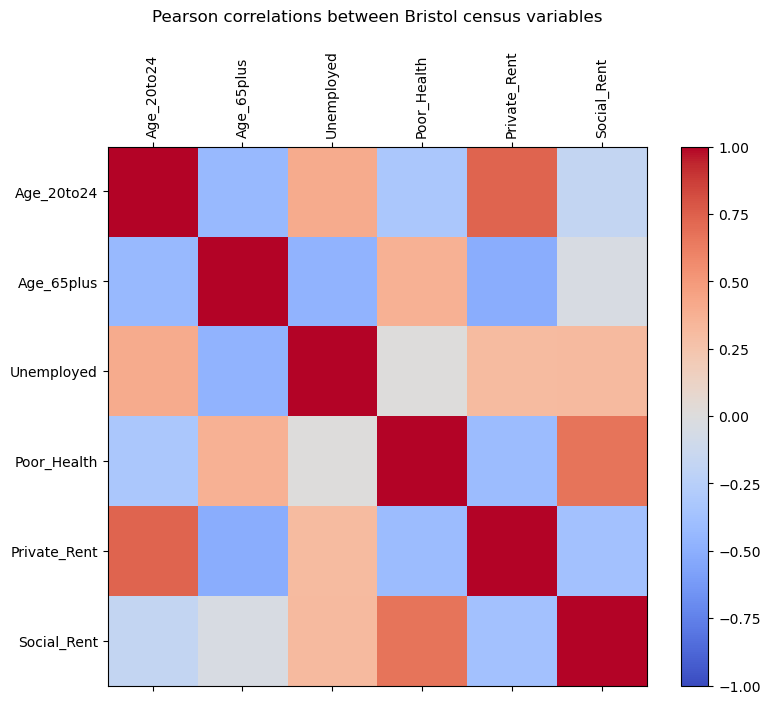

In [69]:
#now i need to be plotting the correlation matrix to make the relationships between the variables easier to see - and i am using the Matplotlib correlation matrix method demonstrated in Lab 6, cell 75
# This should idealy help me see which variables have positive or negative relationships and whether there are any particularly strong correlations

fig, ax = plt.subplots(figsize=(9, 7))

cax = ax.matshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1)

plt.xticks(range(len(variables)), variables, rotation=90)
plt.yticks(range(len(variables)), variables)

fig.colorbar(cax)

plt.title("Pearson correlations between Bristol census variables", pad=20)
plt.show()


In [70]:
# then finally I want to identify which variable pairs have particularly strong correlations again using the correlation threshold approach in Lab 6, cell 77
# I am checking for values above +0.7 or below -0.7, as both positive and negative correlations could suggest overlapping characteristics and the diagonal values of 1 represent each variable's correlation with itself, so these are not relationships between different variables

high_correlations = (correlation_matrix > 0.7) | (correlation_matrix < -0.7)

print("Correlations stronger than +/-0.7:")
print(high_correlations)

Correlations stronger than +/-0.7:
              Age_20to24  Age_65plus  Unemployed  Poor_Health  Private_Rent  \
Age_20to24          True       False       False        False          True   
Age_65plus         False        True       False        False         False   
Unemployed         False       False        True        False         False   
Poor_Health        False       False       False         True         False   
Private_Rent        True       False       False        False          True   
Social_Rent        False       False       False        False         False   

              Social_Rent  
Age_20to24          False  
Age_65plus          False  
Unemployed          False  
Poor_Health         False  
Private_Rent        False  
Social_Rent          True  


#### Findings:
Found that the standardisation checks show that all six variables have means of ~ 0 and standard deviations of 1, so the z-score calculation appears to have worked correctly.And then from the Pearson correlation matrix : the strongest relationship was between the percentage aged 20–24 and private renting (r = 0.729) -this is just above the ±0.7 threshold used in the Lab 6 example, suggesting that these two variables could be representing some similar neighbourhood characteristics i think. Then i also found a moderately strong positive relationship between social renting and reported poor health (r = 0.667). Hence after all this, I have decided to keep all my 6 variables because they represent different census characteristics which are relevant to the classification goal. However, to note, I do recognise that the relationship between younger populations and private renting could give these characteristics some additional influence in the clustering, even after standardisation.

### Step 7: Applying k-means clustering
Now step is that now that I have checked and standardised my six variables, I can start using k-means to group Bristol's Output Areas according to their census characteristics.So using thek-means method explained in Lab 6, I plan to use the 6 standardised percentage variables to group OAs which have similar characteristics.For my  attempt 1, I plan to try using 4 clusters to see how the OAs are divided into groups, then afterwards I will investigate whether a different number of clusters might work better using the elbow method and other comparisons in Step 8 and I will keep the cluster labels separate from the standardised variables because the labels are the result of the clustering, instead than another census variable that should be used as an input.

In [71]:
#now I am using k-means to create my first classification of the Bristol OAs - using the KMeans method demonstrated in Lab 6, cells 92 and 24
#  initially trying 4 clusters, but this is only a starting point and I will compare other values of k in Step 8
#  using the 6 standardised census variables rather than the original percentages because k-means uses distances - then i have  also set a random_state and n_init so that I can reproduce the same results when running the notebook again

kmeans_4 = KMeans(n_clusters=4, random_state=42, n_init=10)

kmeans_4.fit(z_score_df)

labels_4 = kmeans_4.labels_

cluster_centres_4 = kmeans_4.cluster_centers_

print("Number of clusters:", kmeans_4.n_clusters)
print("Number of classified OAs:", len(labels_4))
print("Cluster labels:", np.unique(labels_4))


C:\Users\elisa\miniforge3\envs\ua\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


Number of clusters: 4
Number of classified OAs: 1405
Cluster labels: [0 1 2 3]


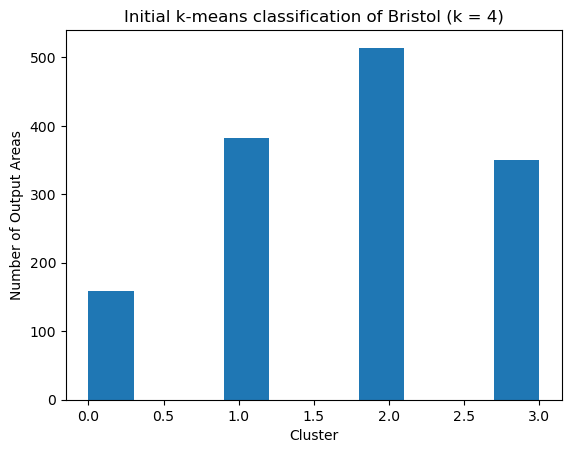

In [72]:
#nowt I want to see how the 1405 Bristol OAs have been divided between the 4 initial clusters- so i am using the histogram method from Lab 6, cell 94
# hopefully this will help me check whether the groups are reasonably sized or if some contain far fewer OAs than others and i plan to examine the clusters more closely after testing the number of clusters in Step 8

plt.hist(labels_4)
plt.xlabel("Cluster")
plt.ylabel("Number of Output Areas")
plt.title("Initial k-means classification of Bristol (k = 4)")
plt.show()


### Step 8: Using the elbow method and comparing different numbers of clusters:
Since i have now run my first k-means classification with 4 clusters, I want to investigate whether this is a suitable number of neighbourhood groups or whether a different number might work better.So, using the elbow method demonstrated in Lab 6 agai, I planto test values of k between 1 and 10 and plot the inertia values to see where adding more clusters starts to make a smaller improvement.Then i am planning to compare the 4 and 5 clusters in more depth by using the silhouette scores + the number of Output Areas assigned to each group. Then i am planning yo use these results to help decide which classification to investigate further. Basically,I don't want to choose the number of clusters just because it gives the lowest inertia (as inertia will generally decrease when more groups are added) hence I also want the final groups to be reasonably meaningful and possible to interpret for my original community service planning question - which is the plan for this ection

C:\Users\elisa\miniforge3\envs\ua\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
C:\Users\elisa\miniforge3\envs\ua\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
C:\Users\elisa\miniforge3\envs\ua\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
C:\Users\elisa\miniforge3\envs\ua\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is k

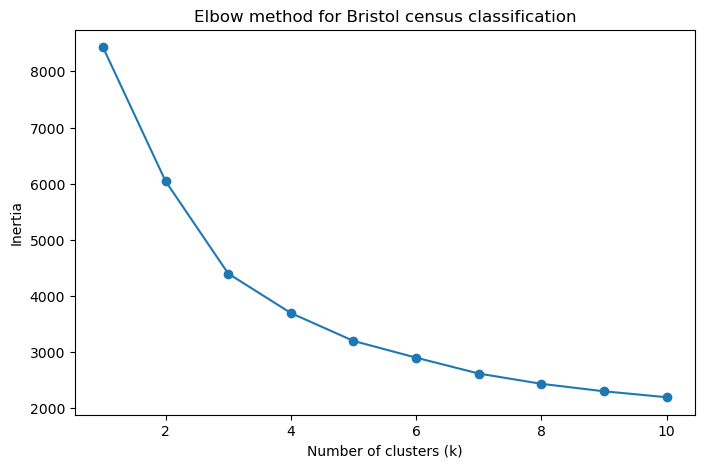

In [73]:
#first i am using the elbow method to help decide how many clusters to use for Bristol - using the elbow plot method demonstrated in Lab 6, cells 22 and 96
# I am testing k values from 1 to 10 to see how much the variation within the clusters decreases and I will look for a point where increasing the number of clusters starts making a smaller difference
# I have kept random_state=42 and n_init=10 the same as my first k-means model:

inertia = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(z_score_df)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia, marker='o')
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow method for Bristol census classification")
plt.show()

In [74]:
#then from the elbow method ,I want to compare an alternative classification using 5 clusters - so I am following the same KMeans method demonstrated in Lab 6, cells 92 and 99
# and I will keep the same six standardised variables and model settings so the comparison with 4 clusters is consistent
# hence I am also keeping the labels separate from z_score_df so they are not included as an input variable

kmeans_5 = KMeans(n_clusters=5, random_state=42, n_init=10)

kmeans_5.fit(z_score_df)

labels_5 = kmeans_5.labels_

cluster_centres_5 = kmeans_5.cluster_centers_

print("Number of clusters:", kmeans_5.n_clusters)
print("Number of classified OAs:", len(labels_5))
print("Cluster labels:", np.unique(labels_5))

C:\Users\elisa\miniforge3\envs\ua\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


Number of clusters: 5
Number of classified OAs: 1405
Cluster labels: [0 1 2 3 4]


In [75]:
#up next is compare how well separated the groups are for k=4 and k=5
# so I am using the silhouette_score method demonstrated in Lab 6, Part 1, cell 22 and a higher score would suggest that the OAs are generally more similar to their own group than to neighbouring groups
# so this should provide another way to compare the two classifications alongside the elbow plot:

silhouette_4 = silhouette_score(z_score_df, labels_4)
silhouette_5 = silhouette_score(z_score_df, labels_5)

print("Silhouette score for 4 clusters:", round(silhouette_4, 3))
print("Silhouette score for 5 clusters:", round(silhouette_5, 3))

Silhouette score for 4 clusters: 0.264
Silhouette score for 5 clusters: 0.273


In [76]:
#Finally I want to compare the inertia values and number of OAs in each classification
# The inertia values should help show whether 5 clusters improves the fit compared with 4
# so I am also checking the group sizes because a very small additional cluster might not be particularly useful- this uses the inertia and cluster membership methods demonstrated in Lab 6

print("Inertia for 4 clusters:", round(kmeans_4.inertia_, 2))
print("Inertia for 5 clusters:", round(kmeans_5.inertia_, 2))

print("Number of OAs in each group (4 clusters):")
print(pd.Series(labels_4).value_counts().sort_index())

print("Number of OAs in each group (5 clusters):")
print(pd.Series(labels_5).value_counts().sort_index())

Inertia for 4 clusters: 3695.61
Inertia for 5 clusters: 3199.07
Number of OAs in each group (4 clusters):
0    159
1    382
2    514
3    350
Name: count, dtype: int64
Number of OAs in each group (5 clusters):
0    399
1    467
2    312
3     80
4    147
Name: count, dtype: int64


#### Findings:
From the elbow plot I found that inertia decreased quite quickly when increasing the number of clusters initially but the improvements then became smaller - there wasn't one completely obvious elbow to me, although around 3–5 clusters seemed worth investigating further.Then by comparing my initial four-cluster model with five clusters, I found that inertia decreased from 3695.61 to 3199.07, while the silhouette score increased slightly from 0.264 to 0.273 - so this suggests that five clusters may provide a slightly better separation of the OAs, although the difference is pretty small.Then i  also noticed that the fivecluster classification had a smaller group of 80 OAs in comparison with the other groups - therefore I want to investigate the characteristics of the clusters further before deciding whether the additional group is actually meaningful for my research question.

### Step 9: Evaluating and interpreting the cluster results

Now that I have compared the four- and five-cluster models, I want to investigate what the groups actually represent before choosing my final classification from those findings. SO naturally, using the cluster evaluation methods in Lab 6, I plan to first look at the cluster centres to see how the characteristics of each group differ from the Bristol average - and then compare the centres for 4 and 5 clusters to see whether the additional group identifies enoguh of a different neighbourhood type. Next on the plan list is to then use PCA, following Lab 6 Part 2, to visualise the six standardised variables in two dimensions - as required int he challenge instructions. Because this should help me investigate how well separated the different groups are, although it is good to note that I dounderstand that a 2-dimensional plot cannot show all the variation in the original six variables.Then finally after comparing the models, I was then planning to investigate the final cluster profiles in more detail using the radial plots demonstrated in Lab 6 - because this should hopefuully help me decide whether the groups can be interpreted meaningfully for my community service planning question.

In [77]:
# First I want to investigate the centres of my initial 4 clusters- by following the cluster centre method from Lab 6, cells 106-107
# and since these values are standardised, positive numbers show characteristics above the Bristol OA average and negative numbers show characteristics below the average
# so this  should help me understand the differences between the groups rather than just looking at their sizes

centres_4 = pd.DataFrame(kmeans_4.cluster_centers_, columns=z_score_df.columns)

centres_4.round(2)

,Age_20to24,Age_65plus,Unemployed,Poor_Health,Private_Rent,Social_Rent
0,2.21,-0.98,1.25,-0.78,1.88,-0.44
1,-0.54,1.03,-0.78,-0.07,-0.65,-0.48
2,-0.05,-0.46,-0.09,-0.48,0.36,-0.49
3,-0.34,-0.01,0.42,1.14,-0.68,1.44


In [78]:
#Next I am doing the same for the 5 cluster model so that I can compare the results - again following Lab 6, cells 106-107, but using the centres from kmeans_5
# I am particularly interested in whether the fifth group has a different combination of census characteristics because will help me decide if using an additional cluster is useful for my classification

centres_5 = pd.DataFrame(kmeans_5.cluster_centers_, columns=z_score_df.columns)

centres_5.round(2)

,Age_20to24,Age_65plus,Unemployed,Poor_Health,Private_Rent,Social_Rent
0,-0.52,0.84,-0.73,-0.21,-0.64,-0.52
1,0.01,-0.49,-0.09,-0.51,0.48,-0.53
2,-0.29,-0.33,0.59,0.76,-0.65,1.34
3,-0.54,1.80,-0.50,2.54,-0.63,1.26
4,2.31,-1.00,1.29,-0.80,1.92,-0.45


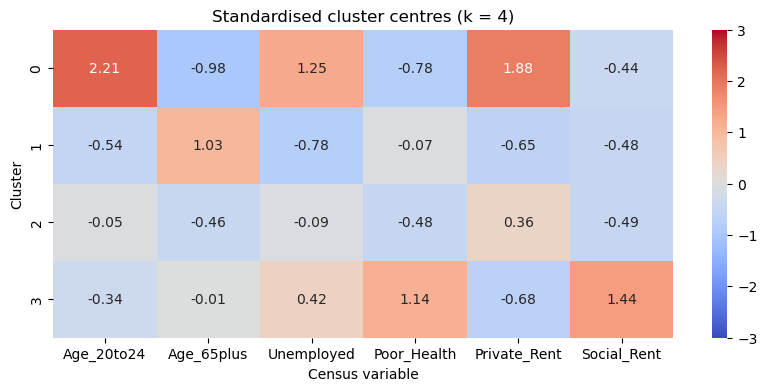

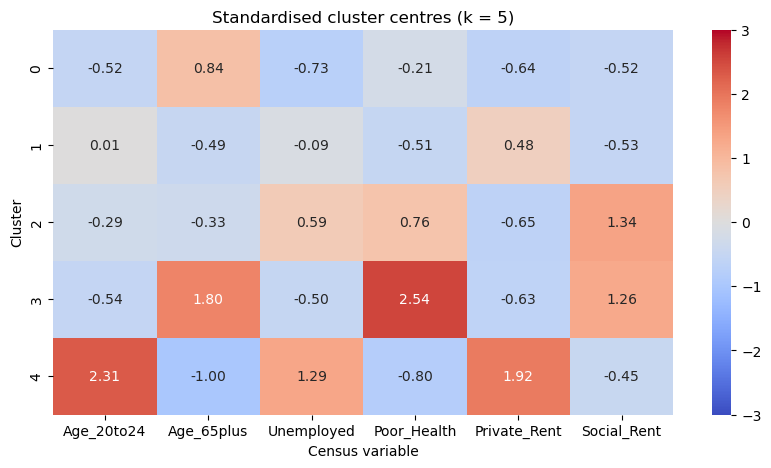

In [82]:
#
# Now I want to compare the standardised cluster centres for the 4 and 5 cluster models visually and to do that, I am using the heatmap method introduced in Lab 6, cell 77, but applying it to the cluster centres from cells 106-109
# hopefully red will show characteristics above the Bristol average and blue will show those below
# and to note that I have used the same colour range for both plots so that the two classifications are easier to compare

plt.figure(figsize=(10, 4))
sns.heatmap(centres_4, annot=True, cmap="coolwarm", center=0, vmin=-3, vmax=3, fmt=".2f")
plt.title("Standardised cluster centres (k = 4)")
plt.xlabel("Census variable")
plt.ylabel("Cluster")
plt.show()

plt.figure(figsize=(10, 5))
sns.heatmap(centres_5, annot=True, cmap="coolwarm", center=0, vmin=-3, vmax=3, fmt=".2f")
plt.title("Standardised cluster centres (k = 5)")
plt.xlabel("Census variable")
plt.ylabel("Cluster")
plt.show()

In [84]:
#up next is applying PCA to the 6 standardised census variables - i am using the PCA method demonstrated in Lab 6, cells 103-104
# reduces the six variables to two principal components which I can then use for visualising the cluster results - and I am using z_score_df rather than the cluster labels because I only want PCA to use the original census characteristics

pca = PCA(n_components=2)

pca.fit(z_score_df)

pca_results = pca.transform(z_score_df)

print("Explained variance for each principal component:")
print(pca.explained_variance_ratio_)

print("Total explained variance:")
print(pca.explained_variance_ratio_.sum())

print("PCA result shape:", pca_results.shape)

Explained variance for each principal component:
[0.45762048 0.28186762]
Total explained variance:
0.7394880951931417
PCA result shape: (1405, 2)


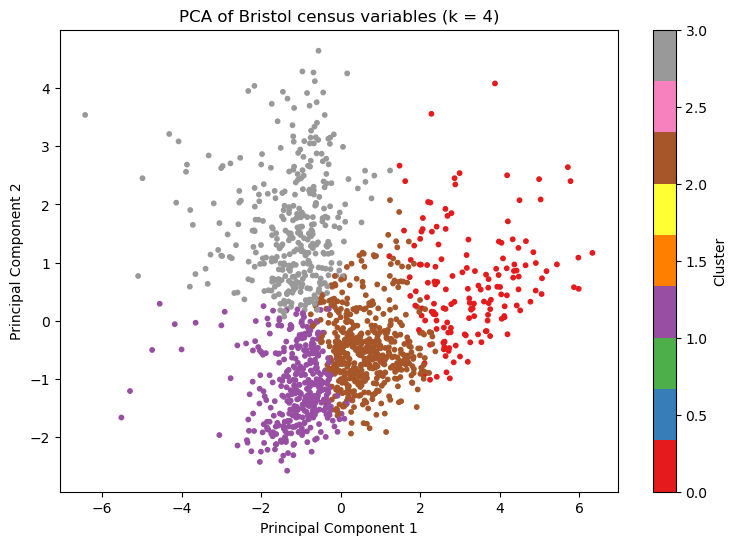

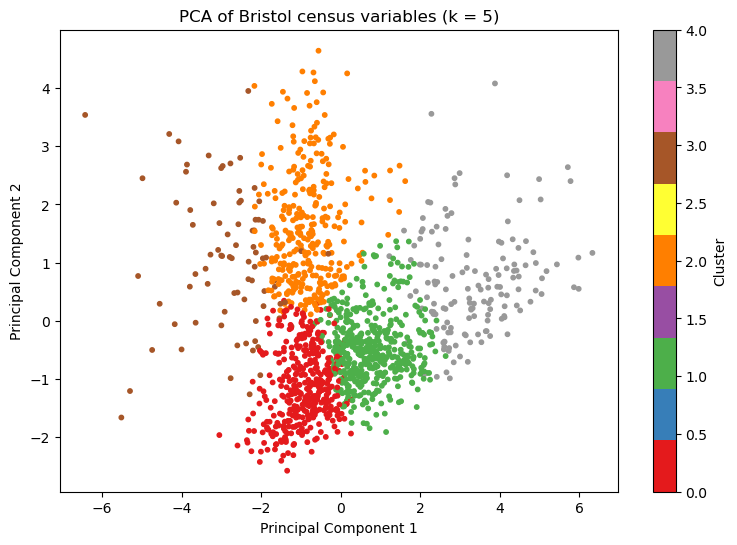

In [85]:
#then finally I want to compare how the 4 and 5 cluster groups look when plotted using the first two principal components - by using the PCA scatter plot approach in Lab 6, cells 103-105
# I am using the same PCA coordinates for both figures, but changing the cluster labels used to colour the points and this should help me see whether the groups are reasonably separated or whether there is considerable overlap

plt.figure(figsize=(9, 6))
plt.scatter(pca_results[:, 0], pca_results[:, 1], c=labels_4, cmap="Set1", s=10)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA of Bristol census variables (k = 4)")
plt.colorbar(label="Cluster")
plt.show()

plt.figure(figsize=(9, 6))
plt.scatter(pca_results[:, 0], pca_results[:, 1], c=labels_5, cmap="Set1", s=10)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA of Bristol census variables (k = 5)")
plt.colorbar(label="Cluster")
plt.show()

#### Examining the cluster profiles in more detail:
From the cluster-centre heatmaps and PCA plots, I can see some differences between the four- and five-cluster results -> the five-cluster model appears to highlight a smaller group with much high reported poor health and a larger older population - which we could note as more relevant to the community service planning aim. Hence, i  now want to examine the actual census percentages for the 5 groups instead of just relying only on their standardised values and I also plan to use the cluster-profile index method introduced in Lab 6 Part 1 and the radial plots from Part 2 in order to help to compare each cluster's characteristics with the Bristol average.Then overall, this should help me decide whether the five groups have sufficiently different characteristics to justify keeping the additional cluster.

In [86]:
#so first I want to look at the actual census percentages for each of the 5 clusters - and I am following the cluster profiling method from Lab 6 Part 1, cell 27
# So I am adding the labels onto a copy of my original Bristol census data, rather than onto z_score_df - and this means I can calculate the average percentage for each group and understand what the clusters actually represent

bristol_5 = bristol_census_data.copy()

bristol_5["Cluster"] = labels_5

cluster_means_5 = bristol_5.groupby("Cluster")[variables].mean()

cluster_means_5.round(2)

,Age_20to24,Age_65plus,Unemployed,Poor_Health,Private_Rent,Social_Rent
Cluster,,,,,,
0,4.86,20.79,1.98,4.38,13.91,7.70
1,9.70,9.25,3.28,3.32,34.39,7.46
2,6.99,10.65,4.69,7.81,13.73,48.16
3,4.75,29.06,2.44,14.09,14.03,46.35
4,30.83,4.89,6.13,2.31,60.98,9.24


In [87]:
# and then next I am comparing each cluster's average percentages with the overall Bristol OA averages - by using the index score approach demonstrated in Lab 6 Part 1, cells 27-29
# An index score of 100 represents the Bristol average, while values above or below 100 show how the cluster differs
# andi am using the six original percentage indicators so the results are easier to interpret in the radial plots

bristol_means = bristol_census_data[variables].mean()

cluster_index_5 = (cluster_means_5 / bristol_means) * 100

cluster_index_5.round(1)

,Age_20to24,Age_65plus,Unemployed,Poor_Health,Private_Rent,Social_Rent
Cluster,,,,,,
0,50.3,153.9,56.9,85.4,54.3,40.6
1,100.5,68.5,94.4,64.8,134.3,39.3
2,72.4,78.8,135.1,152.4,53.6,253.9
3,49.2,215.1,70.2,275.0,54.8,244.4
4,319.4,36.2,176.5,45.0,238.1,48.7


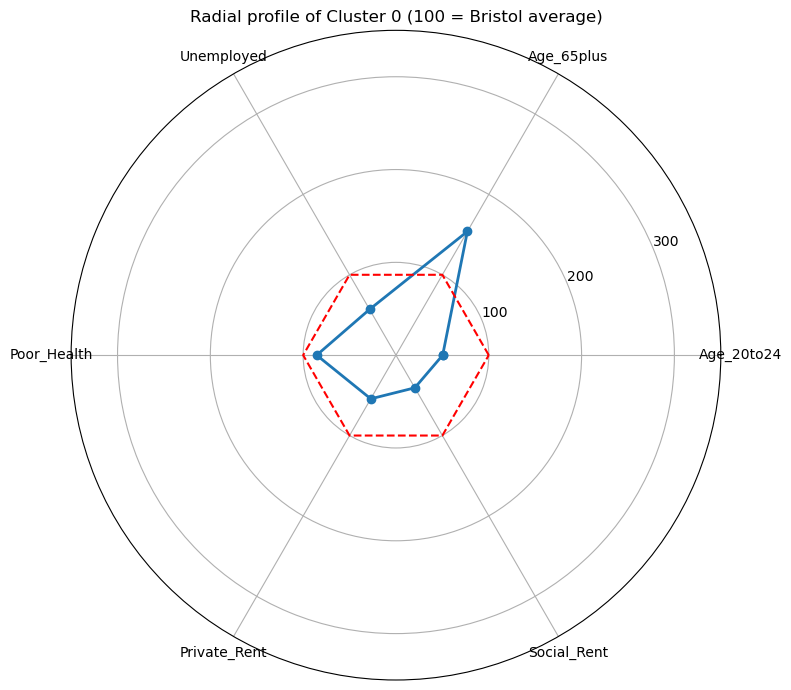

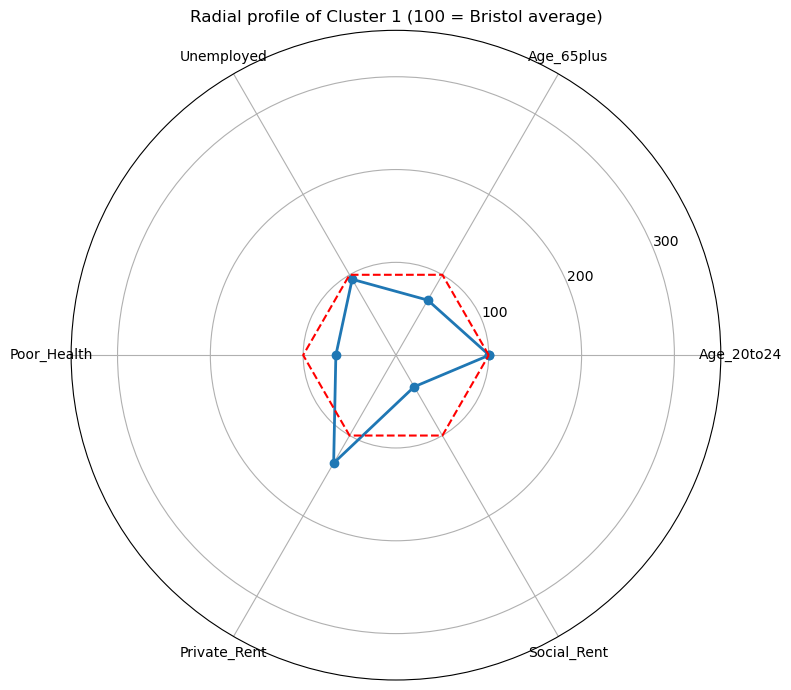

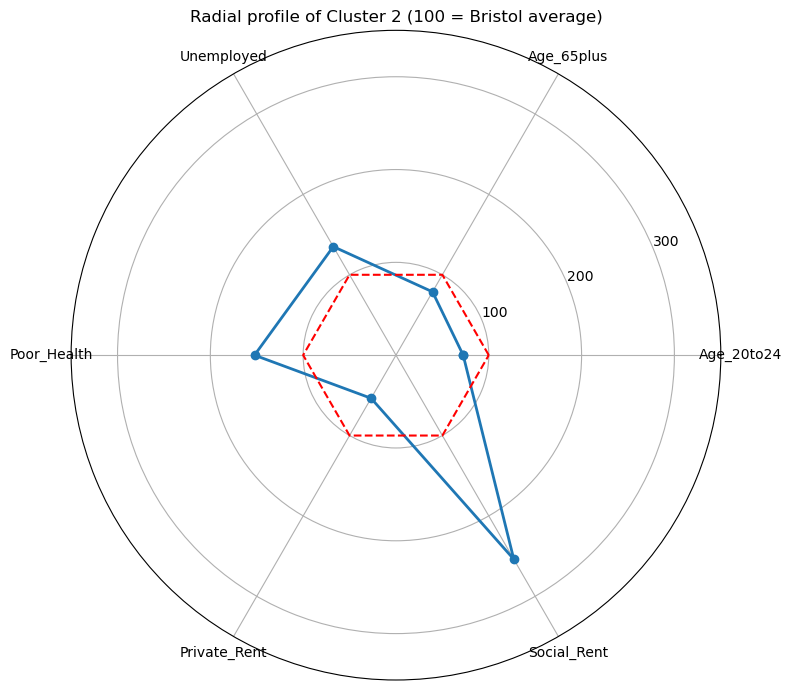

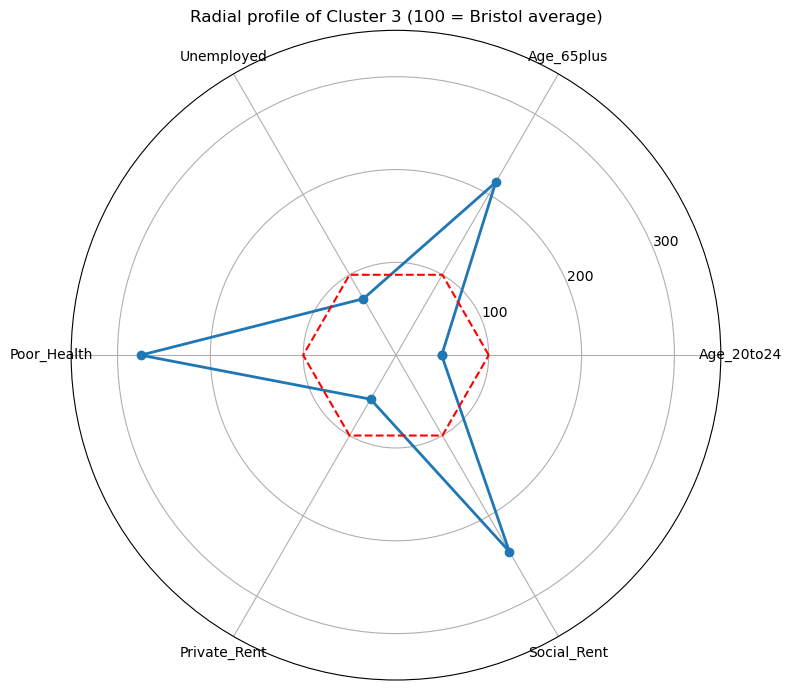

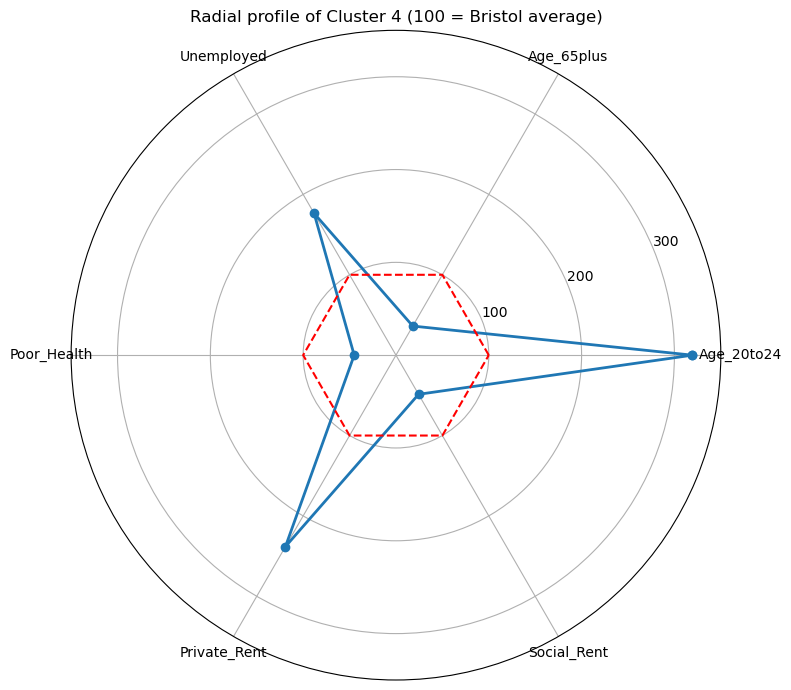

In [89]:
#next up i would like to create radial profile plots for each of the 5 clusters- doing this by following the polar plotting method from Lab 6, cells 108-109, but using the index scores from Lab 6 Part 1
# I am using the same scale for all 5 figures so I can compare the clusters with the dashed line at 100 represents the Bristol OA average for each census variable
# I have repeated the first value at the end to join the radial profile back to its starting point

for cluster in range(5):

    cluster_values = cluster_index_5.loc[cluster].tolist()
    cluster_values = cluster_values + [cluster_values[0]]

    num_features = len(variables)
    theta = np.linspace(0, 2 * np.pi, num_features + 1)

    fig, ax = plt.subplots(figsize=(8, 7), subplot_kw={'projection': 'polar'})

    ax.plot(theta, cluster_values, linewidth=2, marker='o', label=f'Cluster {cluster}')
    ax.plot(theta, [100] * len(theta), linestyle='--', color='red', label='Bristol OA average')

    ax.set_xticks(theta[:-1])
    ax.set_xticklabels(variables)

    ax.set_ylim(0, 350)
    ax.set_yticks([100, 200, 300])

    ax.set_title(f"Radial profile of Cluster {cluster} (100 = Bristol average)")
    

    plt.tight_layout()
    plt.show()

#### Findings and selection of the final model:
After looking at the cluster-centre heatmaps, PCA plots and radial profiles, I think the five-cluster model provides a more useful classification than my original four-cluster model.
The PCA plots show some overlap between the groups suggesting that the classifications are not completely distinct -  although the first 2 principal components explain around 73.95% of the variation. The radial plots and cluster averages also show some meaningful differences between the five groups.
However, one difference I found particularly interesting was between Clusters 2 and 3 because both of them have high proportions of social renting but Cluster 3 has a much older population and a substantially higher proportion reporting bad or very bad health e.g. the average percentage aged 65+ is 29.06% in Cluster 3 compared with 10.65% in Cluster 2.Now this could be relevant to my original community service planning question beacuse areas with these different characteristics may have different potential service requirements.
So overall, based on these results, alongside the slightly higher silhouette score for five clusters (0.273 compared with 0.264) which i mentioned earlier, I have decided to use five clusters for my final classification. However, it is good to note that i do  recognise that the distinction between groups is not perfect and that other values of k could also be reasonable.

### Step 10: Mapping the spatial distribution of the clusters
Now that I have chosen five clusters for my final classification, I want to investigate how the different groups are distributed geographically across Bristol - so by using the mapping methods demonstrated in Lab 6, I plan to join the cluster labels back to the Bristol Output Area boundaries and plot the resulting classification. Despite the groups being created using the 6 census characteristics rather than geographical distances, mapping them should help me analyse if or if not similar types of OAs are concentrated in particular areas or spread throughout the city. Hence, for now I will use the cluster numbers to check that the classification maps correctly and I will then give the groups more descriptive names later on using the census characteristics identified from their cluster profilse

In [90]:
#now that I have decided to use the 5 cluster model, I am preparing the results for mapping- I already added the 5 cluster labels onto a copy of the Bristol census data in Step 9
# Since this dataset still contains the OA boundaries, I can use it directly to map the classification
#i am using the method used in Lab 6 for adding cluster labels back to the geographical data for this:
bristol_final = bristol_5.copy()

# Checking that all the Bristol OAs have been assigned to one of the 5 clusters
print("Number of Output Areas:", len(bristol_final))
print("Missing cluster labels:", bristol_final["Cluster"].isna().sum())

# Checking the number of OAs assigned to each group
print(bristol_final["Cluster"].value_counts().sort_index())

bristol_final.head()


Number of Output Areas: 1405
Missing cluster labels: 0
Cluster
0    399
1    467
2    312
3     80
4    147
Name: count, dtype: int64


,OA21CD,Wardname,geometry,Age_20to24,Age_65plus,Unemployed,Poor_Health,Private_Rent,Social_Rent,Cluster
0,E00073143,Ashley,"POLYGON ((-2.57215 51.46904, -2.57239 51.46911...",8.91,8.64,4.73,3.05,28.38,6.76,1
1,E00073145,Ashley,"POLYGON ((-2.58394 51.46394, -2.58394 51.46388...",13.33,3.81,7.00,3.61,41.14,43.67,2
2,E00073147,Ashley,"POLYGON ((-2.57928 51.46324, -2.57908 51.46340...",7.99,7.43,5.07,5.03,26.32,23.39,1
3,E00073148,Ashley,"POLYGON ((-2.58730 51.46363, -2.58727 51.46355...",15.54,2.70,5.22,3.77,56.34,26.76,4
4,E00073150,Ashley,"POLYGON ((-2.57724 51.46633, -2.57727 51.46632...",11.26,5.84,4.18,4.34,25.65,26.70,1


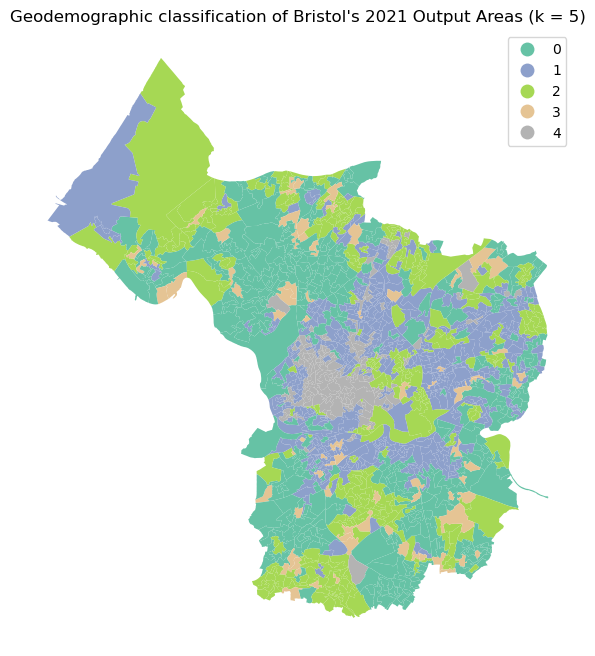

In [91]:
#Next up, I am plotting the spatial distribution of the 5 clusters across Bristol- and i am  following the GeoPandas .plot() mapping method demonstrated in Lab 6 Part 1, cell 25
# every colour represents a different census-based cluster, rather than a different geographical region - and at this stage I am using the cluster numbers, before giving them descriptive names later on
fig, ax = plt.subplots(figsize=(10, 8))

bristol_final.plot(
    column="Cluster",
    categorical=True,
    cmap="Set2",
    legend=True,
    linewidth=0,
    ax=ax
)

ax.set_title("Geodemographic classification of Bristol's 2021 Output Areas (k = 5)")
ax.set_axis_off()

plt.show()

#### Findings:
The map is showing that all 1,405 Bristol Output Areas have been assigned to one of the five clusters, with no missing cluster labels. Then looking at the spatial distribution some of the groups seem to be concentrated in specific parts of Bristol while others are more spread across several areas. e.g. cluster 4 seems to have a stronger concentration around the central part of the city. This is an interesting insight because the clustering was based on the census characteristics rather than geographical location -  so this tells us that OAs with similar characteristics do not necessarily need to be next to one another. Next up, I plan to now give the clusters more descriptive names based on their average census characteristics, rather than leaving them as numerical groups.

### Step 11: Naming the final geodemographic clusters
Now that I have mapped the five clusters my next step is that  I want to give them names which describe their main characteristics instead of just referring to them by their cluster numbers by again using the cluster interpretation and naming examples in Lab 6, so then I will use the average census percentages and radial profiles from Step 9 to decide on appropriate names. As a note, I would like the names to be reflective of the characteristics which differentiates each group from each other especially differences in age, housing tenure, unemployment and reported health. However, I should note here that i also need to be careful not to assume that every resident within an OA has the characteristics shown by the cluster average. After i have assigned the names, I can then go ahead with creating my final classification map showing the geographical distribution of the five neighbourhood types across Bristol.

In [92]:
#first I want to give each of the 5 clusters a more meaningful name based on their census characteristics and so I am using the cluster averages and radial profiles from Step 9 to decide on the names
# using the dictionary and .map() approach demonstrated in Lab 6 Part 1, cell 31 and Part 2, cell 117
# these are descriptions of the average characteristics of each group, rather than every individual person living there

cluster_names = {
    0: "Older, lower-renting",
    1: "Mixed-age, private-renting",
    2: "Social-renting, higher reported poor health",
    3: "Older, social-renting, higher reported poor health",
    4: "Younger, private-renting"
}

# adding the descriptive cluster names onto the final Bristol GeoDataFrame:
bristol_final["Cluster_name"] = bristol_final["Cluster"].map(cluster_names)

# Checking that the new names have been assigned correctly:
print("Missing cluster names:", bristol_final["Cluster_name"].isna().sum())

bristol_final[["OA21CD", "Cluster", "Cluster_name"]].head()


Missing cluster names: 0


,OA21CD,Cluster,Cluster_name
0,E00073143,1,"Mixed-age, private-renting"
1,E00073145,2,"Social-renting, higher reported poor health"
2,E00073147,1,"Mixed-age, private-renting"
3,E00073148,4,"Younger, private-renting"
4,E00073150,1,"Mixed-age, private-renting"


In [93]:
#then next I want to create a table showing the named clusters and their average census percentages by using the cluster profiling method from Lab 6 Part 1, cell 27
# as this will provide numerical evidence for why I gave the five groups their particular names - I am using the original percentages, rather than the standardised values, as these are easier to interpret

final_cluster_summary = bristol_final.groupby(["Cluster", "Cluster_name"])[variables].mean()

final_cluster_summary.round(2)

,,Age_20to24,Age_65plus,Unemployed,Poor_Health,Private_Rent,Social_Rent
Cluster,Cluster_name,,,,,,
0,"Older, lower-renting",4.86,20.79,1.98,4.38,13.91,7.70
1,"Mixed-age, private-renting",9.70,9.25,3.28,3.32,34.39,7.46
2,"Social-renting, higher reported poor health",6.99,10.65,4.69,7.81,13.73,48.16
3,"Older, social-renting, higher reported poor health",4.75,29.06,2.44,14.09,14.03,46.35
4,"Younger, private-renting",30.83,4.89,6.13,2.31,60.98,9.24


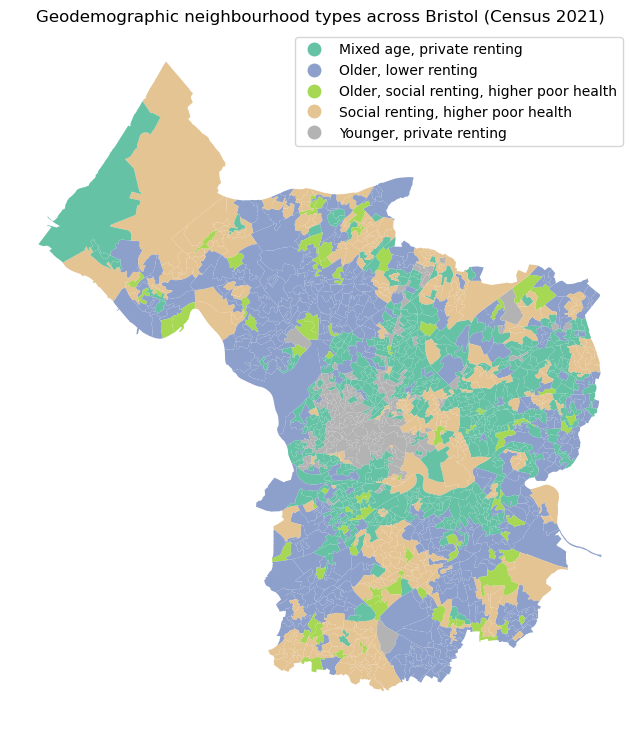

In [94]:
# Finally I am producing the named geodemographic classification map for Bristol - by using the cluster naming and mapping approach from Lab 6, cells 31 and 117
# I am using shorter names in the map legend so they fit more easily, but keeping the fuller names in the summary table
# note that the underlying cluster assignments and census values are not being changed

map_names = {
    0: "Older, lower renting",
    1: "Mixed age, private renting",
    2: "Social renting, higher poor health",
    3: "Older, social renting, higher poor health",
    4: "Younger, private renting"
}

bristol_final["Map_name"] = bristol_final["Cluster"].map(map_names)

fig, ax = plt.subplots(figsize=(12, 9))

bristol_final.plot(
    column="Map_name",
    categorical=True,
    cmap="Set2",
    legend=True,
    linewidth=0,
    ax=ax
)

ax.set_title("Geodemographic neighbourhood types across Bristol (Census 2021)")
ax.set_axis_off()

plt.show()

### Step 12: Reflection, limitations and potential applications:
**Strengths of the classification:**
One strength of my classification is that it uses 4 different Census 2021 topics rather than relying on only 1 type of neighbourhood characteristic and then by combining age, economic activity, general health and housing tenure I have been able to identify 5 different groups with different population and housing profiles. Then by using the 1,405 Output Areas as well, this meant that i couls investigate differences at a pretty good detailed geographical scale. The final map shows that similar neighbourhood types are not necessarily located next to each other which is an interesting finding because k-means used the census characteristics rather than the geographical positions of the OAs. Another strength of this classification is that I tested different numbers of clusters instead of just accepting my first result -although the five-cluster model only had a slightly higher silhouette score then examining the cluster centres and radial profiles showed that the smaller Cluster 3 had a noticeably different age and health profile from Cluster 2. then I also checked for missing values, percentage errors and unusually extreme observations before clustering as good practice which helped me assess the quality of the input data.

**Subjectivity and limitations:**
However, it is good to note that i do recognise that geodemographic classifications involve an amount of subjective decisionse.g. when I chose the 6 indicators because I thought they would be relevant to community service planning but selecting different census variables could actually produce different groups. So, the choice of 5 clusters was also partly based on interpretation, as the elbow plot didn't show one obvious 'optimum'. Then there was also some correlation between the variables, especially the percentages aged 20–24 and privately renting (r = 0.729) and although I did  decided to keep both, this could mean that younger private-renting neighbourhood characteristics have additional influence in the clustering. A second imitation was the presence of extreme observations/outliers - my additional z-score check identified 109 OAs with at least one value more than three standard deviations from the mean and I chose to keep these observations because they could represent actual neighbourhood differences but these extreme values may influence the location of k-means cluster centres. Then the PCA plots also showed some overlap between the clusters with the silhouette scores being fairly low (0.264 and 0.273) which could suggests that the groups are not perfectly separated and that the boundaries between some neighbourhood types are less clear than the final map might suggest There are also limitations with using Output Areas because the classification uses the average characteristics of each OA hence  it can't describe every individual person or household living there - and different people within the same OA may have very different circumstances. The results found could also change if larger geographical units or different boundaries were used. Finally, because this analysis uses 2021 Census data  it does represent characteristics recorded at that time rather than necessarily describing the current population of Bristol which is quite a large limitation for present day applications.

**Potential applications for community service planning:**

Despite these limitations, I think the classification could still be useful as an initial way of investigating differences in community characteristics across Bristol e.g. cluster 3 has a pretty high avg proportion of older residents and people reporting bad or very bad health and this may be useful when considering where to investigate potential health-related or older-person service need as an example. To compare, Cluster 4 has a very high proportion of younger adults and privately renting households which suggests a different population profile which may be relevant to other types of community facilities and planning decisions. However, the classification doesn't directly measure access to services and actual demand or if the existing provision is sufficient. Therefore, I wouldn't use the map on its own to decide where or if new services should be provided - as it would need to be combined with more additional information, such as the locations of existing services, transport accessibility and more detailed local needs assessments.

**Conclusion**

Overall for this challenge, I think the classification has answered my original research question by identifying 5 different geodemographic neighbourhood types across Bristol using 6 Census 2021 indicators from 4 topics.

The five-cluster model was useful for differentiating/distinguishing some different age, health, economic and housing characteristics - especially between the 2 social-renting groups and then mapping these clusters also helped show how the different neighbourhood types are distributed across Bristol.

However, it would be better practice that i state that the classification should be treated as an exploratory tool rather than a definitive description of neighbourhoods or their service needs because the results depend on the selected variables, number of clusters and geographical scale but they could provide a useful starting point for further investigation into community service planning.